In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
from mppi import Parsers as P, Optics as O
from mppi.Utilities import Constants as Const
from mppi.Utilities import Utils
import matplotlib.pyplot as plt
import numpy as np
import os, re

# Transient absorption from the non-linear $\chi$ and comparison with the RT runs

Reconstruction of the pump induced change $\delta\chi^{neq}$ of the probe response from the equilibrium non-linear
susceptibilities extracted in `NL-Chi_Analysis.ipynb`, and comparison with the direct real-time pump-probe simulations of
D. Sangalli (kx16, one run for each pump-probe delay, in `Davide_data/`).

This part comes from the previous version of `NL-Chi_Analysis.ipynb` and has still to be revised:

1. theory of the transient absorption in terms of the non-linear $\chi$ and its translation into the MPPI quantities
   (Eq. (11) of `../References/Pp_and_non_linear_functions.pdf`);
2. `eval_dchi_neq` to be checked against the formula in terms of the MPPI quantities (shifted grids, complex pump
   amplitude, delay convention, shape of the probe of the RT runs), e.g. on the anharmonic oscillator of MPPI;
3. the $\chi_{(1,\pm1)}$ terms are a k discretization error (`NL-Chi_Analysis.ipynb`) and must be dropped;
4. before the comparison with the RT runs remove the INVINT phase $\omega\,dt/2$ consistently from all the $\chi$.

The susceptibilities are taken from the kx16 runs with damping 0.3 eV (the grid of the RT runs): sine (probe only) and
P&p (pump 1e6 kW/m$^2$), 155 probe frequencies 10.000-24.919 eV with step $\omega_P/16$, so the shifted grids
$\omega\pm m\omega_P$ fall exactly on the probe grid.

In [3]:
run_dir = 'kx16_nb100_NoTr_E100'
name_sine = 'pulse-E1_1e3-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100'
name_Pp = 'Pp-Ep_1e3-EP_1e6-PE_1.55-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100'
data_sine = P.YamboNLDBParser(os.path.join(run_dir,name_sine,'ndb.Nonlinear'),verbose=False)
data_Pp = P.YamboNLDBParser(os.path.join(run_dir,name_Pp,'ndb.Nonlinear'),verbose=False)
freq_mix = O.Xn_frequency_mixing(data_Pp,X_order=(1,2),verbose=False)
chi_freqmix = freq_mix.compute_Xn()[0]
chi1_sin = O.Xn_single_frequency(data_sine,X_order=3,verbose=False).compute_Xn()[0][1]
omega = freq_mix.probe_freqs           # Hartree
freqs = omega*Const.HaToeV
omega_P = freq_mix.pump_freq           # Hartree
EP = data_Pp.Efield2[0]['amplitude']   # au
x11m1 = (chi_freqmix[(1,0)] - chi1_sin)/(EP**2/4)
print('%d probe frequencies %.3f-%.3f eV, step/omega_P = %.4f, pump %.3f eV, E0 pump %.3e au'%(
      len(omega),freqs[0],freqs[-1],(omega[1]-omega[0])/omega_P,omega_P*Const.HaToeV,EP))

155 probe frequencies 10.000-24.919 eV, step/omega_P = 0.0625, pump 1.550 eV, E0 pump 1.194e-04 au


## Transient absorption from the non-linear $\chi$

The two descriptions are linked by the following equation
\begin{eqnarray}
\chi^{neq,(1)}[E_P](\omega) &=& \chi^{(1)}(\omega;\omega) + \nonumber \\
&+& \left[ \chi^{(2)}(\omega;\omega_P,\omega-\omega_P)\frac{E_{p}(\omega-\omega_P)}{E_p(\omega)} + 
\chi^{(2)}(\omega;-\omega_P,\omega+\omega_P)\frac{E_{p}(\omega+\omega_P)}{E_p(\omega)}
\right]E_{P}(\omega_P)  + \nonumber \\ &+&\left[   
\chi^{(3)}(\omega;\omega_P,\omega_P,\omega-2\omega_P)\frac{E_{p}(\omega-2\omega_P)}{E_p(\omega)} + 
\chi^{(3)}(\omega;\omega_P,-\omega_P,\omega) + \right. \nonumber \\ &&\left.
\chi^{(3)}(\omega;-\omega_P,-\omega_P,\omega+2\omega_P)\frac{E_{p}(\omega+2\omega_P)}{E_p(\omega)}
\right]E^2_{P}(\omega_P)
\end{eqnarray}

### Translation in terms of the MPPI quantities (MPPI >= 1.3)

`Xn_frequency_mixing(...).compute_Xn()[0][(n,m)]` at the probe frequency $\omega$ is the ratio between the component of
$P$ at $n\omega + m\omega_P$ and the product of the field amplitudes $E(\pm\omega)^{|n|} E(\pm\omega_P)^{|m|}$,
with $E(\omega) = (i E_0/2) e^{i\omega t_0}$ and $E(-\omega) = E(\omega)^*$ (Boyd, Nonlinear Optics, Sec. 1.3).
These quantities include the degeneracy factor: $\chi_{(1,\pm1)} = 2\chi^{(2)}$, $\chi_{(1,\pm2)} = 3\chi^{(3)}$
and the third order part of $\chi_{(1,0)}$ is $6\chi^{(3)}(\omega;\omega,\omega_P,-\omega_P)|E_P(\omega_P)|^2$.
The pump induced change of the response at the frequency $\omega$ reads

$$
\delta\chi(\omega) = \sum_{m=\pm1,\pm2} \chi_{(1,m)}(\omega - m\omega_P)\frac{E_p(\omega - m\omega_P)}{E_p(\omega)}
E_P(\mathrm{sign}(m)\,\omega_P)^{|m|} + \left[\chi_{(1,0)}(\omega) - \chi^{(1)}(\omega)\right]
$$

so the key $(1,m)$ is read at the probe frequency $\omega - m\omega_P$ (shifted grid) and the pump enters with its
complex amplitude $E_P(\omega_P) = (i E_{0P}/2) e^{i\omega_P t_{0P}}$. To be checked against `eval_dchi_neq`.

### Utility functions

In [4]:
def eval_dchi_neq(omega,omega_P,tau,EP,x11,x1m1,x11m1,x12,x1m2):
    """
    We compute the variation of the neq absorption

    Args:
        omega : energy range of the probe (Hartree)
        omega_P : energy of the pump (Hartree)
        tau : time delay of the probe w.r.t. the pump (fs)
        EP : amplitude of the pump
        x11 : chi(omega+omega_P;omega_P,omega)
        x1m1 : chi(omega-omega_P;-omega_P,omega)
        x11m1 : chi(omega,omega_P,-omega_P,omega) extracted as the non-linear part
            of chi(omega)
        x12 : chi(omega+2*omega_P;omega_P,omega_P,omega)
        x1m2 : chi(omega-2*omega_P;-omega_P,-omega_P,omega)
    """
    domega = omega[1]-omega[0]
    ind_oP = round(omega_P/domega)
    omega_eff = omega[2*ind_oP:-2*ind_oP]
    phase = omega_P*tau*Const.FsToAu # corresponds to omega*t/hbar

    F2_1 = x11*np.exp(-1j*phase)
    F2_2 = x1m1*np.exp(1j*phase)
    F2_sum = F2_1[2*ind_oP:] + F2_2[:-2*ind_oP]
    F2_sum_cut = F2_sum[ind_oP:-ind_oP] # cut the part the is not present in the cubic terms

    F3_1 = x12*np.exp(-1j*2*phase)
    F3_2 = x11m1
    F3_3 = x1m2*np.exp(1j*2*phase)
    F3_sum = F3_1[4*ind_oP:] + F3_2[2*ind_oP:-2*ind_oP] + F3_3[:-4*ind_oP]

    dchi_neq = F2_sum_cut*EP+F3_sum*EP**2

    return omega_eff,dchi_neq


def build_delta_dict(path='.'):
    """
    Scan all folders inside `path` and build a dictionary
    using the value contained in 'deltaXX.XXfs' as key.

    Returns
    -------
    dict
        Dictionary of the form

            {
                delta_value: folder_name
            }

    Notes
    -----
    If multiple folders have the same delta value,
    the last one found will overwrite the previous one.
    """

    delta_dict = {}

    # Regular expression used to extract the delta value
    # Example match: delta10.00fs -> 10.00
    pattern = re.compile(r'delta([0-9]+\.?[0-9]*)fs')

    # Loop over all entries in the directory
    for folder in os.listdir(path):

        full_path = os.path.join(path, folder)

        # Process only directories
        if os.path.isdir(full_path):

            # Search for the delta pattern in the folder name
            match = pattern.search(folder)

            if match:

                # Convert extracted value to float
                delta = float(match.group(1))

                # Store folder name in the dictionary
                delta_dict[delta] = folder

    return delta_dict

Now we compare the result for the transient absorption spectrum computed within the two approach.

To this scope we refer to the equation already discussed at the beginning of the notebook that (since we are interested in the variation w.r.t the equilibrium value)
can be written as

\begin{eqnarray}
\delta\chi^{neq,(1)}[E_P](\omega) &=& \chi^{neq,(1)}[E_P](\omega) - \chi^{(1)}(\omega;\omega) = \\
&& \left[ \chi^{(2)}(\omega;\omega_P,\omega-\omega_P)\frac{E_{p}(\omega-\omega_P)}{E_p(\omega)} + 
\chi^{(2)}(\omega;-\omega_P,\omega+\omega_P)\frac{E_{p}(\omega+\omega_P)}{E_p(\omega)}
\right]E_{P}(\omega_P)  + \nonumber \\ &+&\left[   
\chi^{(3)}(\omega;\omega_P,\omega_P,\omega-2\omega_P)\frac{E_{p}(\omega-2\omega_P)}{E_p(\omega)} + 
\chi^{(3)}(\omega;\omega_P,-\omega_P,\omega) + \right. \nonumber \\ &&\left.
\chi^{(3)}(\omega;-\omega_P,-\omega_P,\omega+2\omega_P)\frac{E_{p}(\omega+2\omega_P)}{E_p(\omega)}
\right]E^2_{P}(\omega_P)
\end{eqnarray}

In order to write an equation useful to compute the $\delta\chi^{neq}$ we analyze the previous formula addend by addend.

We parametrize the $\omega$ dependence in terms of the values of the probe, so that the two addends at the second order reads

$$
 \chi^{(2)}(\omega+\omega_P;\omega_P,\omega)\frac{E_{p}(\omega)}{E_p(\omega+\omega_P)} + 
\chi^{(2)}(\omega-\omega_P;-\omega_P,\omega)\frac{E_{p}(\omega)}{E_p(\omega-\omega_P)}
$$

Assuming tha the probe is a delta centred at $t_0$ in the time domain, its FT is given by $e^{i\omega t_0}$ so the ratios of probe fields simplify to

$$
\chi^{(2)}(\omega+\omega_P;\omega_P,\omega)e^{-i\omega_P \, t_0} + 
\chi^{(2)}(\omega-\omega_P;-\omega_P,\omega)e^{i\omega_P \, t_0}
$$

In the same way we can rewrite the third order addends as

$$
\chi^{(3)}(\omega;\omega_P,-\omega_P,\omega) +
\chi^{(3)}(\omega+2\omega_P;\omega_P,\omega_P,\omega)e^{-2i\omega_P \, t_0} + 
\chi^{(3)}(\omega-2\omega_P;-\omega_P,-\omega_P,\omega)e^{2i\omega_P \, t_0}
$$

The function `eval_dchi_neq` builds these terms on the common frequency range.
It has still to be checked against the formula in terms of the MPPI quantities written above.

In [5]:
x11 = chi_freqmix[(1,1)]
x1m1 = chi_freqmix[(1,-1)]
x12 = chi_freqmix[(1,2)]
x1m2 = chi_freqmix[(1,-2)]

RT results of D. Sangalli (kx16): absorption spectrum for each pump-probe delay

In [6]:
path = 'Davide_data/20250312_Report_simulations_data_kx16_ball/'
deltas_folder = build_delta_dict(path=path)
deltas = sorted(deltas_folder.keys())
deltas

[5.25,
 8.5,
 8.75,
 9.0,
 9.25,
 9.5,
 9.75,
 10.0,
 10.25,
 10.5,
 10.75,
 11.0,
 11.25,
 11.5,
 11.75,
 12.0,
 12.25,
 12.5,
 12.75,
 13.0,
 13.25,
 13.5,
 13.75,
 14.0,
 14.25,
 14.5,
 14.75,
 15.0,
 15.25,
 15.5,
 15.75,
 16.0,
 16.25,
 16.5,
 16.75,
 17.0,
 17.25,
 17.5,
 17.75,
 18.0,
 18.25,
 18.5,
 18.75,
 19.0,
 19.25,
 19.5,
 19.75,
 20.0,
 20.25,
 20.5,
 20.75,
 21.0,
 21.25,
 21.5,
 21.75,
 22.0,
 22.25,
 22.5,
 22.75,
 23.0,
 23.25,
 23.5,
 23.75,
 24.0]

Parse file Davide_data/20250312_Report_simulations_data_kx16_ball/td-ip-ber_3.0as_inv_1-15b_qsf90pi1.56_6.0E9_deph0.0eV_delta5.25fs_Pp_NL/o-abs_0-50eV_sm0.6eV.YPP-eps_along_E


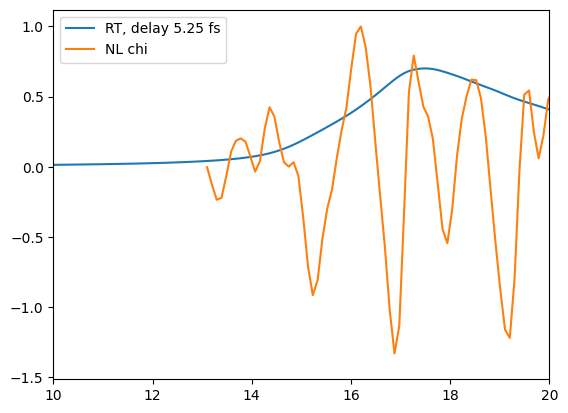

In [7]:
tau = deltas[0]

data = P.YamboOutputParser.from_file(os.path.join(path,deltas_folder[tau],'o-abs_0-50eV_sm0.6eV.YPP-eps_along_E'))['YPP-eps_along_E']
energy = data['col1']
eps_im = data['col2']
omega_eff, dchi_neq = eval_dchi_neq(omega,omega_P,tau,EP,x11,x1m1,x11m1,x12,x1m2)

abs_chi = np.imag(dchi_neq)/max(np.imag(dchi_neq))

plt.plot(energy,eps_im/max(eps_im),label='RT, delay %s fs'%tau)
plt.plot(omega_eff*Const.HaToeV,abs_chi,label='NL chi')
plt.xlim(10,20)
plt.legend()